**Eye-Tracking & Neurocognitive Intelligence | Eye-Movement Modelling & Advanced AI | Presented by: Reza Saadatyar (2026)**

**01 | GazeBase Source, Target and Participant-Disjoint Protocol**

![GazeBase source selection, four task protocols, model inputs and independent-person partitions](../../images/01_data_and_experimental_protocol.svg)

**Objective:** Prepare four-class GazeBase source-task recognition (FXS, HSS, RAN and TEX). These labels identify recording protocols, not cognition, comprehension or diagnosis. The original recording remains the classification unit; participants remain the independent groups.

**Data acquisition:** The new Section 01A provides an optional 20-person Colab source preflight with a persistent Google Drive cache. This section has not yet been executed in the published notebook; the recorded ten-person pilot outputs below remain unchanged.

**Recorded pilot evidence:** The saved execution selected **10 complete participants and 40 original recordings** from GazeBase v2.0, Round 1 / Session 1. It produced **40 recording-level feature rows** and **960 temporal windows with shape (960, 256, 4)**. No classification model was trained in this notebook.

**Independent data contract:** Reuse only original GazeBase CSVs and the read-only source adapter from Eye-Tracking Foundations. This project maintains separate features, windows, splits and outputs. The pilot assigns **6/2/2 people** to Train/Validation/Test (seed 17); its Test is exploratory.

**Scientific boundary:** The 24 windows per record are correlated samples, not new participants. Train-only normalisation prevents fitting on Validation or Test. A later 20/30-person evaluation needs additional source recordings, fresh reserved Test participants and regeneration of dependent model outputs. Source identifiers, labels and recording duration are not predictors.


**00. Colab Repository Setup**


In [1]:
# ======================== 00. Colab Repository Setup =========================

# -------------------------- 1. Repository Checkout ---------------------------
from pathlib import Path
import subprocess

repo_url = "https://github.com/RezaSaadatyar/Eye-Tracking-Neurocognitive-Intelligence.git"
repo_path = Path("/content") / repo_url.rsplit("/", 1)[-1].removesuffix(".git")
if not repo_path.exists():
    subprocess.run(["git", "clone", "-q", repo_url, str(repo_path)], check=True)

# ---------------------------- 2. Open Repository -----------------------------
%cd {repo_path}


/content/Eye-Tracking-Neurocognitive-Intelligence


**01. Imports and Research Environment**


In [2]:
# =================== 01. Imports and Research Environment ====================

# ------------------------ 1. Study Environment Setup -------------------------
from python_modules.core.colab_setup import setup_colab
root = setup_colab("eye_movement_modelling")

# ------------------------ 2. Read-Only Source Adapter ------------------------
import sys
source_module = str(root / "eye_tracking_foundations" / "code" / "src")
if source_module not in sys.path:
    sys.path.insert(0, source_module)

# ----------------------- 3. Scientific Data Libraries ------------------------
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from core.plot_style import plot_style, save_figure
from core.output_download import download_outputs_from_colab

# --------------------------- 4. Modelling Utilities --------------------------
from gaze_source import discover_records
from s2_data import (
    TASKS, CHANNELS, FEATURES, participant_split,
    build_source_tables, normalise_train_only, save_protocol,
)

# ----------------------------- 5. Output Folder ------------------------------
output_dir = root / "eye_movement_modelling" / "output"
output_dir.mkdir(parents=True, exist_ok=True)
plot_style(font_family="DejaVu Sans", figure_dpi=100, figure_size=(9, 4))
print("Project output directory:", output_dir)
print("Shared original GazeBase source:", root / "data" / "raw" / "gazebase")


Repository updated.
Project output directory: /content/Eye-Tracking-Neurocognitive-Intelligence/eye_movement_modelling/output
Shared original GazeBase source: /content/Eye-Tracking-Neurocognitive-Intelligence/data/raw/gazebase


**01A. Acquire and Verify Original GazeBase CSVs in Colab**

This is a **data-acquisition preflight only**, not a new model run or a change to the ten-person pilot. The cell checks Round 1 / Session 1, original source IDs **1001–1020** and the four FXS/HSS/RAN/TEX files per person (**80 CSVs**). It restores compatible source files from your mounted Google Drive cache before attempting a download. Missing files are extracted selectively from GazeBase v2.0. The downloader first tries official Figshare endpoints. If they return no data, it can use a byte-equivalent archive mirror, but accepts the download only after checking the published source size and MD5. Other tasks and rounds are not saved.

The official archive is approximately **6.7 GB**. The cell checks available Colab disk space, validates the published source checksum, reports basic source validity and timestamp diagnostics, and caches the selected files in **your own Google Drive**. It writes only `01_source_acquisition_preflight.csv` to this project's output directory. **It does not fit models, change Train/Validation/Test assignments, open Test predictions or upload raw data to GitHub.**

Run this cell after the repository setup and imports. The remaining Notebook 01 scientific pipeline retains `MAX_PARTICIPANTS = 10` until a larger evaluation protocol is explicitly established.

**Download failure handling:** An empty HTTP response is not a valid download. The downloader tries alternative endpoints, supports matching HTTP Range responses for resumption and reports endpoint diagnostics when none succeeds. If this Colab runtime blocks every source, use a fresh runtime or provide the official ZIP at `/content/gazebase_source_download/GazeBase_v2_0.zip` and rerun Section 01A. The source archive is still checksum-verified before use.


In [ ]:
# ================== 01A. GazeBase Source Acquisition Preflight =============

# ------------------- 1. Persistent Google Drive Source Cache ----------------
from google.colab import drive
from s2_acquisition import ensure_gazebase_preflight

drive.mount("/content/drive")
drive_data_cache = (
    Path("/content/drive/MyDrive") /
    "Eye-Tracking-Neurocognitive-Intelligence" /
    "eye_movement_modelling" / "gazebase_source_cache"
)
drive_data_cache.mkdir(parents=True, exist_ok=True)

# ------------------ 2. Select Data-Only Trial Participants ------------------
PREFLIGHT_SOURCE_IDS = tuple(range(1001, 1021))  # Source IDs, not split labels
preflight = ensure_gazebase_preflight(
    raw_root=root / "data" / "raw" / "gazebase",
    cache_root=drive_data_cache,
    download_root=Path("/content") / "gazebase_source_download",
    output_csv=output_dir / "01_source_acquisition_preflight.csv",
    requested_ids=PREFLIGHT_SOURCE_IDS,
)

# --------------------- 3. Report Source Audit Only ---------------------------
print("Validated independent source people:", preflight.source_id.nunique())
print("Validated Round 1 / Session 1 recordings:", len(preflight))
print("Tasks:", sorted(preflight.task.unique()))
print("Drive cache:", drive_data_cache)
display(preflight.head(8))


**02. Select the Original GazeBase Recordings**

The recorded pilot selected **10 complete original source IDs (1001–1010)**, with one FXS, HSS, RAN and TEX recording per person, giving **40 source records**. Selection uses original ID order rather than a random population sample. The next run may change `MAX_PARTICIPANTS` only when the additional original CSVs are available; an incomplete requested cohort raises an error.

No output from Eye-Tracking Foundations is imported. Shared source data do not make the two projects a single statistical experiment.


In [3]:
# ================== 02. Select Original GazeBase Recordings ==================

# ------------------------ 1. User-Facing Cohort Size -------------------------
MAX_PARTICIPANTS = 10
SEED = 17
source_dir = root / "data" / "raw" / "gazebase"

# ----------------------- 2. Discover Complete Records ------------------------
inventory = discover_records(
    source_dir, round_id=1, session_id=1,
    tasks=TASKS, max_participants=MAX_PARTICIPANTS,
)
actual_people = inventory["participant_id"].nunique()
if actual_people != MAX_PARTICIPANTS:
    raise ValueError(
        f"Requested {MAX_PARTICIPANTS} complete participants but only "
        f"{actual_people} are available. Add authorised GazeBase source CSVs "
        "before increasing the cohort size."
    )
inventory.drop(columns=["path"]).to_csv(
    output_dir / "01_source_inventory.csv", index=False,
)
print("Complete participants:", actual_people)
print("Original task recordings:", len(inventory))
print("Source task labels:", sorted(inventory.task.unique()))
display(inventory[["record_id", "participant_id", "task", "relative_file"]].head(12))


Complete participants: 10
Original task recordings: 40
Source task labels: ['FXS', 'HSS', 'RAN', 'TEX']


,record_id,participant_id,task,relative_file
0,S_1001_S1_FXS,001,FXS,GazeBase_v2_0/Round_1/Subject_1001/S1_Fixation...
1,S_1001_S1_HSS,001,HSS,GazeBase_v2_0/Round_1/Subject_1001/S1_Horizont...
2,S_1001_S1_RAN,001,RAN,GazeBase_v2_0/Round_1/Subject_1001/S1_Random_S...
3,S_1001_S1_TEX,001,TEX,GazeBase_v2_0/Round_1/Subject_1001/S1_Reading/...
4,S_1002_S1_FXS,002,FXS,GazeBase_v2_0/Round_1/Subject_1002/S1_Fixation...
5,S_1002_S1_HSS,002,HSS,GazeBase_v2_0/Round_1/Subject_1002/S1_Horizont...
6,S_1002_S1_RAN,002,RAN,GazeBase_v2_0/Round_1/Subject_1002/S1_Random_S...
7,S_1002_S1_TEX,002,TEX,GazeBase_v2_0/Round_1/Subject_1002/S1_Reading/...
8,S_1003_S1_FXS,003,FXS,GazeBase_v2_0/Round_1/Subject_1003/S1_Fixation...
9,S_1003_S1_HSS,003,HSS,GazeBase_v2_0/Round_1/Subject_1003/S1_Horizont...


**03. Register Participant-Disjoint Train, Validation and Test**

The recorded **seed-17 pilot** has **6 Train people (24 recordings), 2 Validation people (8 recordings) and 2 Test people (8 recordings)**. The saved participant sets are Train: `003, 004, 006, 007, 009, 010`; Validation: `002, 008`; Test: `001, 005`. All four source tasks remain together within each person's partition.

These are observed assignments for this pilot, not mandatory counts or identities for future cohorts. The two-person pilot Test cannot establish stable unseen-person population performance. The larger run must reserve previously unseen source IDs for the main Test before model evaluation.


In [4]:
# ================= 03. Assign Independent Participant Groups =================

# ------------------------- 1. Frozen Split Registry --------------------------
split = participant_split(inventory, seed=SEED)
split.to_csv(output_dir / "01_split_assignments.csv", index=False)

# ------------------------ 2. Verify and Display Scope ------------------------
print("Study purpose:", split.study_purpose.iloc[0])
print("Independent people per partition:")
display(split.groupby("split").agg(
    n_people=("participant_id", "nunique"),
    n_task_records=("record_id", "count"),
).reset_index())
print("Participant sets:")
for role in ("train", "validation", "test"):
    people = sorted(split.loc[split.split.eq(role), "participant_id"].unique())
    print(role, ":", people)


Study purpose: pilot
Independent people per partition:


,split,n_people,n_task_records
0,test,2,8
1,train,6,24
2,validation,2,8


Participant sets:
train : ['003', '004', '006', '007', '009', '010']
validation : ['002', '008']
test : ['001', '005']


**04. Build Record Features and Contiguous Motion Windows**

The recorded run constructed **40 feature rows** and **960 windows**, with **24 windows per recording** at the configured cap and **256 original samples per window**. The four sequence channels are median-centred `x/y` (degrees of visual angle) and their first differences. Valid windows do not cross an invalid gaze sample or an adjacent timestamp gap greater than 5 ms; selection does not add independent participants.

The first 12 displayed records show varied source validity and much higher 95th-percentile step speeds for some horizontal-saccade recordings than for fixation recordings. These are **descriptive source measurements**, not model discrimination evidence. Extreme adjacent-step speeds identified in Eye-Tracking Foundations remain a reason to inspect the full saved distribution before interpreting motion-sensitive models; this preview does not establish their cause.


In [5]:
# ================== 04. Construct Gaze Features and Windows ==================

# ---------------------- 1. Bounded Sequence Parameters -----------------------
WINDOW_SAMPLES = 256
MAX_WINDOWS_PER_RECORD = 24

# --------------------- 2. Process Original Source Files ----------------------
record_features, windows, window_record_ids, window_labels = (
    build_source_tables(
        inventory, split, window_samples=WINDOW_SAMPLES,
        max_windows_per_record=MAX_WINDOWS_PER_RECORD,
    )
)
record_features.to_csv(output_dir / "01_record_features.csv", index=False)

# ------------------------- 3. Show Input Dimensions --------------------------
print("Source feature rows:", len(record_features))
print("Temporal windows / samples / channels:", windows.shape)
print("Raw temporal channels:", CHANNELS)
display(record_features[[
    "record_id", "participant_id", "task", "split",
    "valid_fraction", "n_windows", "speed_p95_dva_s",
]].head(12))


Source feature rows: 40
Temporal windows / samples / channels: (960, 256, 4)
Raw temporal channels: ('relative_x_dva', 'relative_y_dva', 'delta_x_dva', 'delta_y_dva')


,record_id,participant_id,task,split,valid_fraction,n_windows,speed_p95_dva_s
0,S_1001_S1_FXS,001,FXS,test,0.967566,24,23.710742
1,S_1001_S1_HSS,001,HSS,test,0.996387,24,334.517138
2,S_1001_S1_RAN,001,RAN,test,0.986779,24,108.202030
3,S_1001_S1_TEX,001,TEX,test,0.966713,24,149.099253
4,S_1002_S1_FXS,002,FXS,validation,0.968356,24,33.517744
5,S_1002_S1_HSS,002,HSS,validation,0.990959,24,346.461856
6,S_1002_S1_RAN,002,RAN,validation,0.990869,24,101.349886
7,S_1002_S1_TEX,002,TEX,validation,0.985557,24,128.550220
8,S_1003_S1_FXS,003,FXS,train,0.986599,24,15.018685
9,S_1003_S1_HSS,003,HSS,train,0.997424,24,308.394018


**05. Fit Temporal Normalisation on Training Participants Only**

The output contains **960 normalised windows of shape (960, 256, 4)**. The recorded training-derived channel means and scales are displayed below and saved in `01_sequence_normalisation.csv`. The computation fits normalisation parameters on Train windows only and applies them unchanged to Validation and Test. No participant ID or task label is used as a temporal input channel.

Classical models independently fit imputation and applicable scaling in Train-only scikit-learn Pipelines. The sequence archive retains window-to-record mappings for recording-level aggregation.


In [6]:
# ==================== 05. Train-Only Motion Normalisation ====================

# ------------------------ 1. Calculate Train Moments -------------------------
scaled, centre, scale = normalise_train_only(
    windows, window_record_ids, split,
)
np.savez_compressed(
    output_dir / "01_sequence_windows.npz",
    x=scaled, y=window_labels, record_id=window_record_ids,
)
pd.DataFrame({
    "channel": CHANNELS, "train_mean": centre, "train_scale": scale,
}).to_csv(output_dir / "01_sequence_normalisation.csv", index=False)

# ------------------------- 2. Show Train Statistics --------------------------
print("Normalised windows:", scaled.shape)
display(pd.DataFrame({
    "channel": CHANNELS, "train_mean": centre, "train_scale": scale,
}))
print("No Validation or Test examples were fitted during normalisation.")


Normalised windows: (960, 256, 4)


,channel,train_mean,train_scale
0,relative_x_dva,-0.032463,3.530716
1,relative_y_dva,-0.044809,1.515575
2,delta_x_dva,0.001343,0.113939
3,delta_y_dva,0.001773,0.053771


No Validation or Test examples were fitted during normalisation.


**06. Save the Protocol Table and Source Overview**

The executed pilot saved `01_protocol.csv`, a human-readable, one-row configuration table covering the selected GazeBase source, four task labels, participant count, split seed, window length, temporal channels and exploratory Test role. The recorded chart shows **24 Train, 8 Validation and 8 Test recordings**; each partition contains all four task protocols.

These files define a reproducible input contract, not a model-performance result or a claim of independent validation. The protocol CSV and source-distribution plot are included in the recorded seven-file Notebook 01 output package.


,Setting
dataset,GazeBase_v2_0
round_id,1
session_id,1
task_labels,"[FXS, HSS, RAN, TEX]"
max_participants,10
split_seed,17
window_samples,256
max_windows_per_record,24
purpose,pilot
test_role,pilot_exploratory


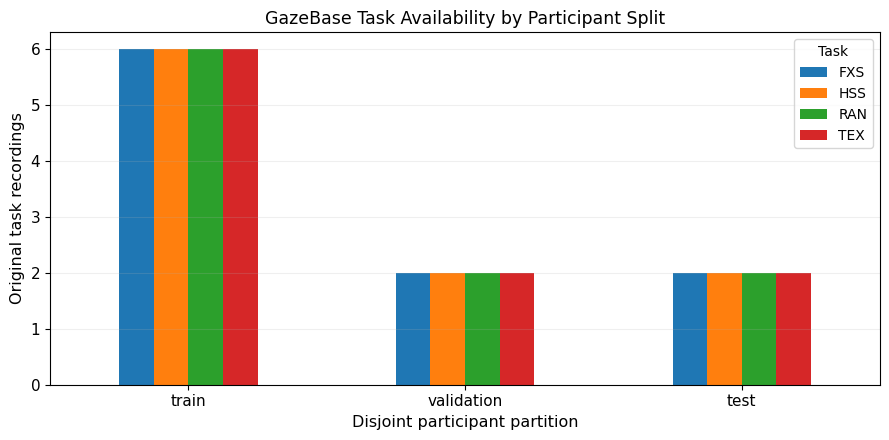

In [7]:
# =================== 06. Save Protocol and Source Overview ===================

# -------------------- 1. Record Explicit Scientific Setup --------------------
protocol = save_protocol(
    output_dir / "01_protocol.csv",
    participants=MAX_PARTICIPANTS, seed=SEED,
    window_samples=WINDOW_SAMPLES,
    max_windows_per_record=MAX_WINDOWS_PER_RECORD,
    purpose=split.study_purpose.iloc[0],
)
display(pd.Series(protocol, name="Setting").to_frame())

# ---------------------- 2. Visualise Independent Units -----------------------
counts = split.groupby(["split", "task"]).size().unstack(fill_value=0)
fig, ax = plt.subplots(figsize=(9, 4.5))
counts.reindex(["train", "validation", "test"]).plot(
    kind="bar", ax=ax, rot=0,
)
ax.set(xlabel="Disjoint participant partition",
       ylabel="Original task recordings",
       title="GazeBase Task Availability by Participant Split")
ax.legend(title="Task")
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
save_figure(fig, output_dir / "01_source_distribution.png")
plt.show()


**07. Scientific Interpretation and Output Download**

The original-data pilot produced **40 feature rows** and **960 temporal windows (256 samples × 4 channels)** from **40 recordings by 10 participants**. It assigned **6/2/2 independent participants** to Train/Validation/Test and fitted temporal normalisation on Train windows only.

This notebook does not fit a classifier or compute classification scores. **Notebook 02 has separately recorded exploratory Validation results** for four classical candidates on 8 recordings from 2 people. Its scores must not be interpreted as an independent population estimate or confused with the not-yet-run final Test evaluation.

Notebook 02 consumes `01_record_features.csv`, `01_split_assignments.csv` and `01_protocol.csv`; Notebooks 03/04 also require `01_sequence_windows.npz`. A changed cohort or feature recipe requires regenerating compatible downstream results. The final cell lists the owned output files and ZIP path once. The new data-preflight CSV is included only after Section 01A is actually executed.


In [8]:
# ====================== 07. Export Current Notebook 01 =======================
download_outputs_from_colab("eye_movement_modelling/output", "01")


------------------------------------------------------------------------
Notebook 01
Files packaged: 7
  + 01_protocol.csv
  + 01_record_features.csv
  + 01_sequence_normalisation.csv
  + 01_sequence_windows.npz
  + 01_source_distribution.png
  + 01_source_inventory.csv
  + 01_split_assignments.csv
Download ZIP from Colab Contents: /content/eye_movement_modelling_Notebook_01_Outputs.zip
